# Week 8: How Accurate Is the AVM, and Where Does It Fail?

The AVM is the automated valuation model built over the past weeks: it estimates what a home will sell for
from its size, location and other recorded details. This notebook asks how close those estimates are, and
where they are not close at all.

**How to read this notebook.** It answers four questions, in order:

| Question | Where | Short answer |
|---|---|---|
| 1. How accurate is it overall? | [Steps 3-4](#step-3-five-accuracy-measures-five-models) | XGBoost misses a typical May 2026 home by 7.38% - that is MdAPE, the typical percent error |
| 2. Which homes does it price well, and which does it miss? | [Steps 5-11](#step-5-accuracy-by-price-level) | Best in the middle of the market and in lower-priced inland counties; the top of the market is about 2.2x worse |
| 3. Does that accuracy hold over time? | [Steps 12-15](#step-12-re-run-at-three-earlier-months) | The model ranking holds at all 4 scored months |
| 4. What are the limits? | [Step 17](#step-17-what-this-week-establishes) and the closing cell | Settings tuned on one month; no claims below county level; a hard ceiling on the most expensive homes |

**Ground rules.** Nothing is tuned here and no model is re-picked. The test month, May 2026, was scored once
per model in Week 7 and is never scored again - those saved predictions are reused. Splits are chronological,
the random seed is 42, everything the models learn is fit on training rows only, and errors are reported both
in dollars and as a percent of the sale price.

### Step 1: Load the saved results

**What this shows:** Loads the predictions that five finished models made for the test month, May 2026, together with this week's result tables. Nothing is re-trained and the test month is never scored a second time.

**Results:** Everything that follows rests on 12,015 May 2026 sales that no model saw while it was being trained.

In [1]:
# Produces: the loaded tables, the saved test-month predictions, and the shared plotting style
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mt
import seaborn as sns
from IPython.display import Markdown, display

import features as ft, model_pipeline as mp, plot_style as ps

warnings.filterwarnings('ignore', category=FutureWarning)
ps.apply_style()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 220)

MODELS = ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']
HEADLINE = 'XGBoost'          # saved production model (outputs/models/best_model.joblib)
MIN_N = 200                   # minimum group size for a reportable segment conclusion

summary = pd.read_csv('outputs/metrics_summary.csv')
band    = pd.read_csv('outputs/week8_by_price_band.csv')
county  = pd.read_csv('outputs/week8_by_county.csv')
zips    = pd.read_csv('outputs/week8_by_zip.csv', dtype={'group': 'object'})
contr   = pd.read_csv('outputs/week8_band_contrasts.csv')
back    = pd.read_csv('outputs/week8_backtest.csv')
w7comp  = pd.read_csv('outputs/week7_comparison.csv')

preds = pd.read_csv('scratch/week7_test_predictions.csv')
v3 = pd.read_csv('outputs/03_features_v3.csv', dtype={'PostalCode': 'object', 'SchoolDistrict': 'object'})
test = v3.loc[v3['split'].eq('test')].reset_index(drop=True)
y_test = test['ClosePrice'].to_numpy(float)
# Train-only price bounds, recomputed from the data (never typed from memory).
_train_rows, TRAIN_BOUNDS = mp.filter_train_prices(v3.loc[v3['split'].eq('train')])
TRAIN_CAP = float(TRAIN_BOUNDS[1])

usd  = lambda v: f'${v:,.0f}'
pctf = lambda v: f'{v:.2%}'
print(f'Test month 2026-05: {len(test):,} homes | saved predictions for {len(MODELS)} frozen models')

Test month 2026-05: 12,015 homes | saved predictions for 5 frozen models


### Step 2: Confirm the numbers still match

**What this shows:** The saved predictions are re-scored here and compared with last week's published results at full decimal precision. If any model's numbers had changed, this cell would stop the notebook with an error.

**Results:** All five models reproduce last week's May 2026 results. The largest relative difference is 9e-10, which comes from how one model's predictions were stored in its file, not from a model changing.

In [2]:
# Produces: the regression-gate table proving all five models still match Week 7
assert np.array_equal(preds['ClosePrice'].to_numpy(float), y_test), 'prediction/test row alignment broken'

gate_rows, worst = [], {}
for m in MODELS:
    got = ft.full_metrics(y_test, preds[m].to_numpy(float))
    exp = w7comp.loc[w7comp['model'].eq(m)].iloc[0]
    rel = {k: abs(got[k] - float(exp[k])) / abs(float(exp[k])) for k in ['R2', 'MAE', 'RMSE', 'MAPE', 'MdAPE']}
    worst[m] = max(rel.values())
    gate_rows.append({'model': m, **got, 'max_rel_diff_vs_week7': worst[m]})

gate = pd.DataFrame(gate_rows)
# XGBoost's Week 7 predictions were produced as float32, so its CSV round-trip carries ~1e-7
# relative precision. The other four models must be bit-exact.
TOL = {m: (1e-6 if m == 'XGBoost' else 1e-12) for m in MODELS}
failed = {m: worst[m] for m in MODELS if worst[m] >= TOL[m]}
assert not failed, f'REGRESSION GATE FAILED: {failed}'

display(gate.style.format({'R2': '{:.4f}', 'MAE': '${:,.0f}', 'RMSE': '${:,.0f}',
                           'MAPE': '{:.2%}', 'MdAPE': '{:.2%}',
                           'max_rel_diff_vs_week7': '{:.1e}'}).hide(axis='index'))
display(Markdown(
    f'**Gate PASSED.** All five models reproduce `week7_comparison.csv`. Four match to machine precision '
    f'(largest relative difference {max(worst[m] for m in MODELS if m != "XGBoost"):.1e}); '
    f'`XGBoost` matches to {worst["XGBoost"]:.1e} relative because its Week 7 predictions were produced as '
    f'`float32` and round-tripped through CSV - its MdAPE itself agrees to '
    f'{abs(ft.full_metrics(y_test, preds["XGBoost"].to_numpy(float))["MdAPE"] - float(w7comp.loc[w7comp.model.eq("XGBoost"), "MdAPE"].iloc[0])):.1e}. '
    f'That is a storage-precision artifact, not model drift.'))

model,R2,MAE,RMSE,MAPE,MdAPE,max_rel_diff_vs_week7
LR,0.5024,"$228,645","$1,182,624",18.18%,9.58%,1.5e-16
DT,0.4303,"$256,543","$1,265,392",18.63%,10.32%,9.4e-16
RF,0.4445,"$220,621","$1,249,535",15.91%,8.19%,3.4e-16
LightGBM,0.4931,"$198,928","$1,193,608",15.05%,7.40%,5.5e-16
XGBoost,0.4934,"$198,830","$1,193,246",15.68%,7.38%,9.0e-10


**Gate PASSED.** All five models reproduce `week7_comparison.csv`. Four match to machine precision (largest relative difference 9.4e-16); `XGBoost` matches to 9.0e-10 relative because its Week 7 predictions were produced as `float32` and round-tripped through CSV - its MdAPE itself agrees to 8.3e-17. That is a storage-precision artifact, not model drift.

### Step 3: Five accuracy measures, five models

**What this shows:** One row per model and five ways of measuring the same errors. The headline measure is MdAPE, the typical percent error: the miss on the middle home, which a handful of enormous sales cannot distort.

**Results:** In May 2026 XGBoost is the most accurate of the five - a typical miss of 7.38% and \$198,830 on average - against 10.32% for the weakest, a single decision tree (DT in the table).

In [3]:
# Produces: the Week 8 deliverable table: R2, MAE, RMSE, MAPE and MdAPE for five models
show = summary[['model', 'feature_set', 'n_estimators', 'n_features', 'n_test',
                'R2', 'MAE', 'RMSE', 'MAPE', 'MdAPE']].copy()
display(show.style.format({'R2': '{:.4f}', 'MAE': '${:,.0f}', 'RMSE': '${:,.0f}',
                           'MAPE': '{:.2%}', 'MdAPE': '{:.2%}', 'n_test': '{:,}',
                           'n_features': '{:,}', 'n_estimators': '{:,}'})
        .background_gradient(subset=['MdAPE'], cmap='RdYlGn_r').hide(axis='index'))

best = summary.sort_values('MdAPE').iloc[0]
worst_m = summary.sort_values('MdAPE').iloc[-1]
r2_best = summary.sort_values('R2', ascending=False).iloc[0]
display(Markdown(f'''
**Reading the table.** {best["model"]} ({best["feature_set"]}) has the lowest typical error at
**{best["MdAPE"]:.2%} MdAPE** (MAE {usd(best["MAE"])}), and {worst_m["model"]} the highest at
{worst_m["MdAPE"]:.2%} (MAE {usd(worst_m["MAE"])}) - a spread of
{100*(worst_m["MdAPE"] - best["MdAPE"]):.2f} pp.

**The metrics disagree, and that disagreement is informative.** {r2_best["model"]} wins on R2
({r2_best["R2"]:.4f} vs {best["R2"]:.4f}) while losing badly on MdAPE
({r2_best["MdAPE"]:.2%} vs {best["MdAPE"]:.2%}). Tree models cannot predict above the training price
cap, so on the handful of sales above it they are capped while the linear model extrapolates; squared-error
metrics reward that, median percentage error does not. MAPE sits above MdAPE for every model
(e.g. {best["model"]}: {best["MAPE"]:.2%} vs {best["MdAPE"]:.2%}), which is the signature of a
right-skewed error distribution - a minority of badly-missed homes pulls the mean.
'''))

model,feature_set,n_estimators,n_features,n_test,R2,MAE,RMSE,MAPE,MdAPE
LR,F3,1,"1,483","12,015",0.5024,"$228,645","$1,182,624",18.18%,9.58%
DT,F0,1,"1,110","12,015",0.4303,"$256,543","$1,265,392",18.63%,10.32%
RF,F0,200,"1,110","12,015",0.4445,"$220,621","$1,249,535",15.91%,8.19%
LightGBM,F0,"2,001",21,"12,015",0.4931,"$198,928","$1,193,608",15.05%,7.40%
XGBoost,F0,"1,022",21,"12,015",0.4934,"$198,830","$1,193,246",15.68%,7.38%



**Reading the table.** XGBoost (F0) has the lowest typical error at
**7.38% MdAPE** (MAE $198,830), and DT the highest at
10.32% (MAE $256,543) - a spread of
2.94 pp.

**The metrics disagree, and that disagreement is informative.** LR wins on R2
(0.5024 vs 0.4934) while losing badly on MdAPE
(9.58% vs 7.38%). Tree models cannot predict above the training price
cap, so on the handful of sales above it they are capped while the linear model extrapolates; squared-error
metrics reward that, median percentage error does not. MAPE sits above MdAPE for every model
(e.g. XGBoost: 15.68% vs 7.38%), which is the signature of a
right-skewed error distribution - a minority of badly-missed homes pulls the mean.


### Step 4: The same numbers as bars

**What this shows:** The table above drawn as bars, one bar per model. Shorter is better in the left two panels, typical percent error and average dollar error; the right panel is R-squared, the share of price variation a model explains, which rewards getting the largest sales right.

**Results:** R-squared puts Linear Regression first at 0.5024, while on typical percent error it is only fourth at 9.58%. The cause is a price ceiling on the tree-based models, shown in Step 16, not a better model.

saved: outputs/figures/w8_fig1_model_metrics.png


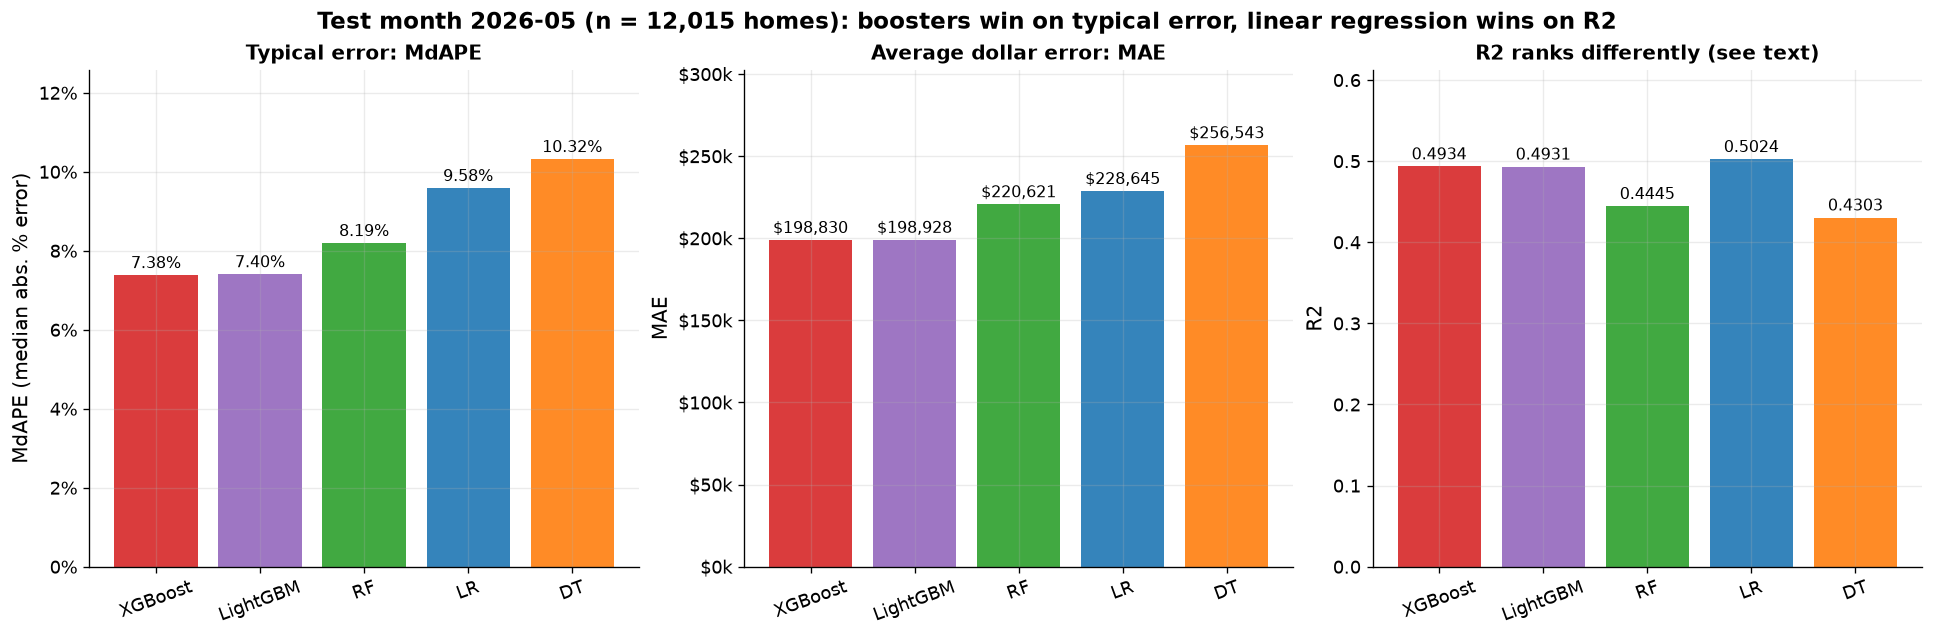

In [4]:
# Produces: Figure 1 - the five models compared on MdAPE, MAE and R2
# Figure 1: five-model test metrics (w8_fig1)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
order = summary.sort_values('MdAPE')
colors = [ps.MODEL_COLORS[m] for m in order['model']]

for ax, col, fmt, title, ylab in [
    (axes[0], 'MdAPE', '{:.2%}', 'Typical error: MdAPE', 'MdAPE (median abs. % error)'),
    (axes[1], 'MAE',   '${:,.0f}', 'Average dollar error: MAE', 'MAE'),
    (axes[2], 'R2',    '{:.4f}',  'R2 ranks differently (see text)', 'R2')]:
    b = ax.bar(order['model'], order[col], color=colors, alpha=0.9)
    ax.bar_label(b, labels=[fmt.format(v) for v in order[col]], fontsize=9.5, padding=2)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel(ylab)
    ax.tick_params(axis='x', rotation=20)
axes[0].yaxis.set_major_formatter(mt.PercentFormatter(xmax=1, decimals=0))
axes[1].yaxis.set_major_formatter(ps.usd)
axes[0].set_ylim(0, order['MdAPE'].max() * 1.22)
axes[1].set_ylim(0, order['MAE'].max() * 1.18)
axes[2].set_ylim(0, order['R2'].max() * 1.22)
fig.suptitle(f'Test month 2026-05 (n = {int(summary["n_test"].iloc[0]):,} homes): boosters win on typical error, '
             f'linear regression wins on R2', fontsize=14, fontweight='bold')
print('saved:', ps.save(fig, 'w8_fig1_model_metrics.png'))
plt.show()

### Step 5: Accuracy by price level

**What this shows:** The test month split by price two ways: into fifths of the training price range, so the test month never sets its own boundaries, and into round dollar bands. Each row carries its number of sales and a range of uncertainty.

**Results:** In May 2026 accuracy is best in the middle of the market - Q2 575-785k, a typical error of 5.33% - and worst at the top, 11.60% for Q5 >1.59M.

In [5]:
# Produces: three price-band tables: quintiles for XGBoost, fixed bands for XGBoost, quintiles for all models
def band_view(scope, model):
    s = band[band.scope.eq(scope) & band.model.eq(model)].sort_values('order')
    v = s[['group', 'n', 'pct_of_test', 'median_actual_price', 'MdAPE', 'MdAPE_ci_lo_pct',
           'MdAPE_ci_hi_pct', 'median_signed_pct_error', 'MAE', 'MAPE', 'RMSE', 'R2', 'below_min_n']].copy()
    v['MdAPE_95CI'] = [f'[{lo:.2f}, {hi:.2f}] pp' for lo, hi in zip(v['MdAPE_ci_lo_pct'], v['MdAPE_ci_hi_pct'])]
    return v.drop(columns=['MdAPE_ci_lo_pct', 'MdAPE_ci_hi_pct'])

FMT = {'n': '{:,}', 'pct_of_test': '{:.1f}%', 'median_actual_price': '${:,.0f}', 'MdAPE': '{:.2%}',
       'median_signed_pct_error': '{:+.2f}%', 'MAE': '${:,.0f}', 'MAPE': '{:.2%}',
       'RMSE': '${:,.0f}', 'R2': '{:.3f}'}

display(Markdown(f'### 3a. Train-only price quintiles - {HEADLINE} (headline model)'))
display(band_view('train_quintile', HEADLINE).style.format(FMT)
        .background_gradient(subset=['MdAPE'], cmap='RdYlGn_r').hide(axis='index'))
display(Markdown(f'### 3b. Fixed dollar bands - {HEADLINE}'))
display(band_view('fixed_band', HEADLINE).style.format(FMT)
        .background_gradient(subset=['MdAPE'], cmap='RdYlGn_r').hide(axis='index'))

display(Markdown('### 3c. MdAPE by train quintile, all five models'))
piv = (band[band.scope.eq('train_quintile')]
       .pivot_table(index=['order', 'group', 'n'], columns='model', values='MdAPE')
       .reset_index().sort_values('order').drop(columns='order'))
display(piv[['group', 'n'] + MODELS].style.format({m: '{:.2%}' for m in MODELS} | {'n': '{:,}'})
        .background_gradient(subset=MODELS, cmap='RdYlGn_r', axis=None).hide(axis='index'))

### 3a. Train-only price quintiles - XGBoost (headline model)

group,n,pct_of_test,median_actual_price,MdAPE,median_signed_pct_error,MAE,MAPE,RMSE,R2,below_min_n,MdAPE_95CI
Q1 <575k,"2,333",19.4%,"$442,000",6.63%,+2.08%,"$53,830",35.19%,"$131,448",-0.636,False,"[6.27, 7.06] pp"
Q2 575-785k,"2,205",18.4%,"$680,000",5.33%,-0.13%,"$56,309",8.31%,"$88,344",-1.122,False,"[5.06, 5.67] pp"
"Q3 785-1,050k","2,225",18.5%,"$890,000",6.02%,-1.43%,"$78,923",8.75%,"$118,403",-1.741,False,"[5.75, 6.30] pp"
"Q4 1,050k-1.59M","2,548",21.2%,"$1,275,000",8.08%,-2.79%,"$140,406",10.90%,"$196,949",-0.666,False,"[7.67, 8.54] pp"
Q5 >1.59M,"2,704",22.5%,"$2,270,000",11.60%,-6.63%,"$593,873",15.07%,"$2,501,468",0.277,False,"[11.07, 12.18] pp"


### 3b. Fixed dollar bands - XGBoost

group,n,pct_of_test,median_actual_price,MdAPE,median_signed_pct_error,MAE,MAPE,RMSE,R2,below_min_n,MdAPE_95CI
<500k,"1,644",13.7%,"$400,000",7.51%,+3.05%,"$56,004",46.12%,"$147,886",-1.788,False,"[6.87, 8.06] pp"
500k-750k,"2,511",20.9%,"$626,000",5.45%,-0.13%,"$52,696",8.47%,"$80,619",-0.283,False,"[5.17, 5.72] pp"
750k-1M,"2,368",19.7%,"$859,000",5.85%,-1.06%,"$73,917",8.55%,"$112,678",-1.538,False,"[5.61, 6.11] pp"
1M-1.5M,"2,464",20.5%,"$1,220,485",7.92%,-2.46%,"$133,406",10.86%,"$188,585",-0.829,False,"[7.57, 8.47] pp"
1.5M-3M,"2,271",18.9%,"$1,888,000",10.16%,-5.02%,"$262,778",12.90%,"$365,955",0.188,False,"[9.60, 10.68] pp"
>3M,757,6.3%,"$4,050,000",15.90%,-12.38%,"$1,405,592",19.85%,"$4,687,499",0.077,False,"[14.62, 17.18] pp"


### 3c. MdAPE by train quintile, all five models

group,n,LR,DT,RF,LightGBM,XGBoost
Q1 <575k,"2,333",8.93%,9.62%,7.21%,6.59%,6.63%
Q2 575-785k,"2,205",7.96%,8.19%,6.10%,5.36%,5.33%
"Q3 785-1,050k","2,225",7.89%,8.53%,6.60%,5.95%,6.02%
"Q4 1,050k-1.59M","2,548",9.73%,11.07%,8.83%,8.19%,8.08%
Q5 >1.59M,"2,704",14.10%,15.69%,12.73%,11.85%,11.60%


### Step 6: Every model struggles with expensive homes

**What this shows:** One line per model, with both price splits side by side. Left to right runs from the cheapest group of homes to the most expensive, and higher means a larger typical percent error.

**Results:** All five lines rise the same way, so this is a property of the problem rather than of one algorithm. In May 2026 the gap between the best and worst price group is 6.27 points, far wider than the 0.81 points between the best model and Random Forest.

saved: outputs/figures/w8_fig2_mdape_by_price_band.png


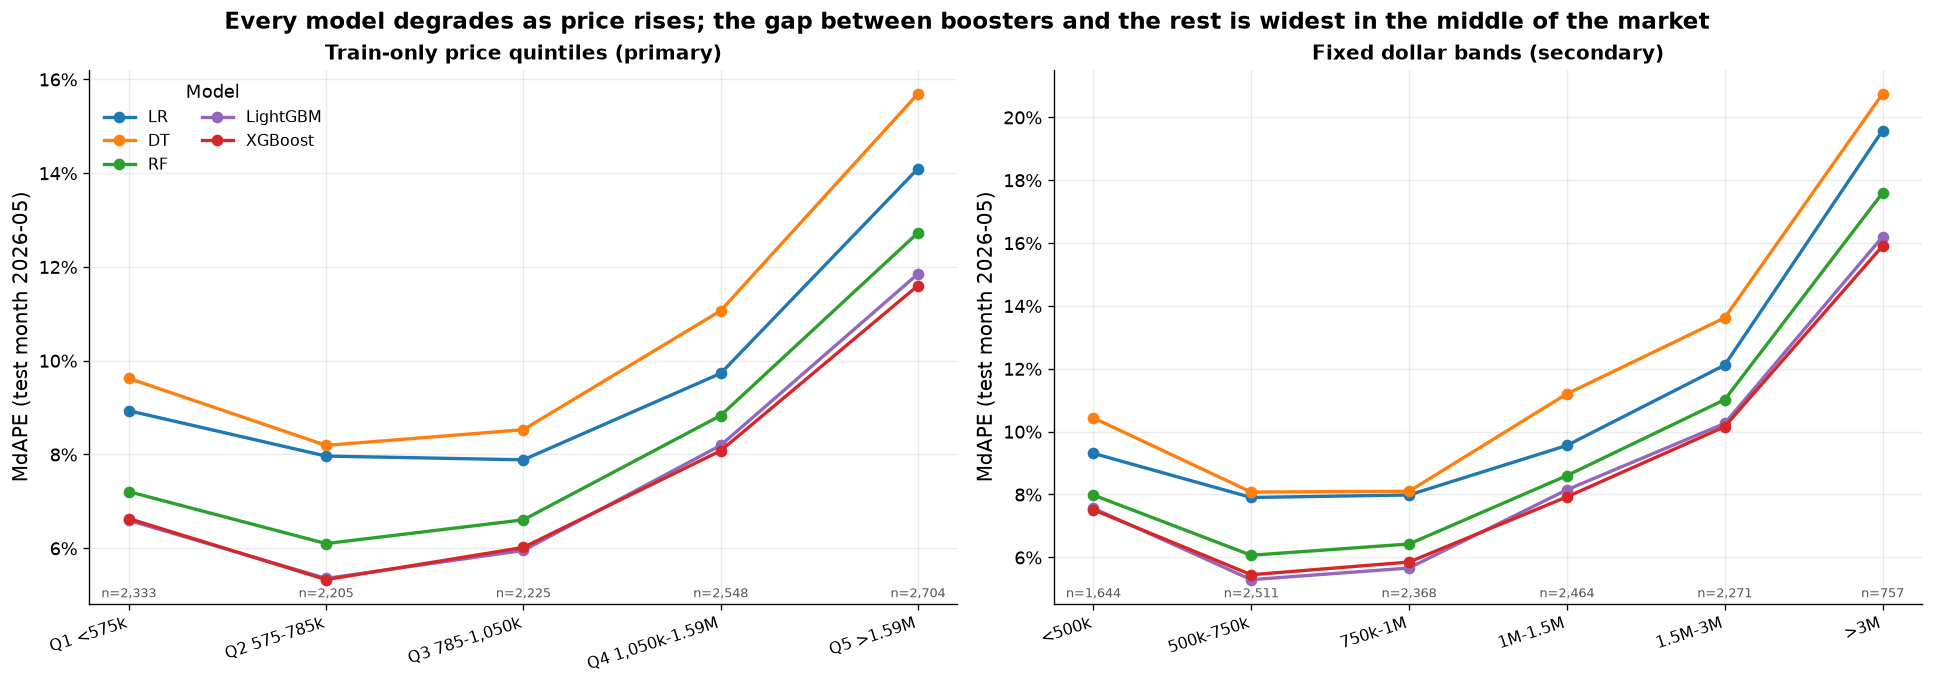

In [6]:
# Produces: Figure 2 - MdAPE across price bands for all five models, both band schemes
# Figure 2: MdAPE by price band, all models, both band schemes (w8_fig2)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), constrained_layout=True)
for ax, scope, title in [(axes[0], 'train_quintile', 'Train-only price quintiles (primary)'),
                         (axes[1], 'fixed_band', 'Fixed dollar bands (secondary)')]:
    s = band[band.scope.eq(scope)].sort_values('order')
    labs = s.drop_duplicates('order')['group'].tolist()
    for m in MODELS:
        sm = s[s.model.eq(m)]
        ax.plot(range(len(labs)), sm['MdAPE'], marker='o', lw=2, ms=6,
                color=ps.MODEL_COLORS[m], label=m)
    ax.set_xticks(range(len(labs)))
    ax.set_xticklabels(labs, rotation=18, ha='right', fontsize=9.5)
    ax.yaxis.set_major_formatter(mt.PercentFormatter(xmax=1, decimals=0))
    ax.set_ylabel('MdAPE (test month 2026-05)')
    ax.set_title(title, fontsize=12)
    ns = s.drop_duplicates('order')['n'].tolist()
    for i, nn in enumerate(ns):
        ax.annotate(f'n={nn:,}', (i, ax.get_ylim()[0]), xytext=(0, 4), textcoords='offset points',
                    ha='center', fontsize=8, color='#555555')
axes[0].legend(title='Model', ncols=2, fontsize=9.5)
fig.suptitle('Every model degrades as price rises; the gap between boosters and the rest is widest '
             'in the middle of the market', fontsize=14, fontweight='bold')
print('saved:', ps.save(fig, 'w8_fig2_mdape_by_price_band.png'))
plt.show()

### Step 7: The error leans one way

**What this shows:** On the left, the typical percent error for each dollar band with a bar showing its uncertainty. On the right, the middle error with its sign kept: above the dashed zero line the model prices homes too high, below it too low.

**Results:** The misses are not symmetric. In May 2026 the <500k band is priced about 3.0 percent too high and the >3M band about 12.4 percent too low.

saved: outputs/figures/w8_fig3_band_bias.png


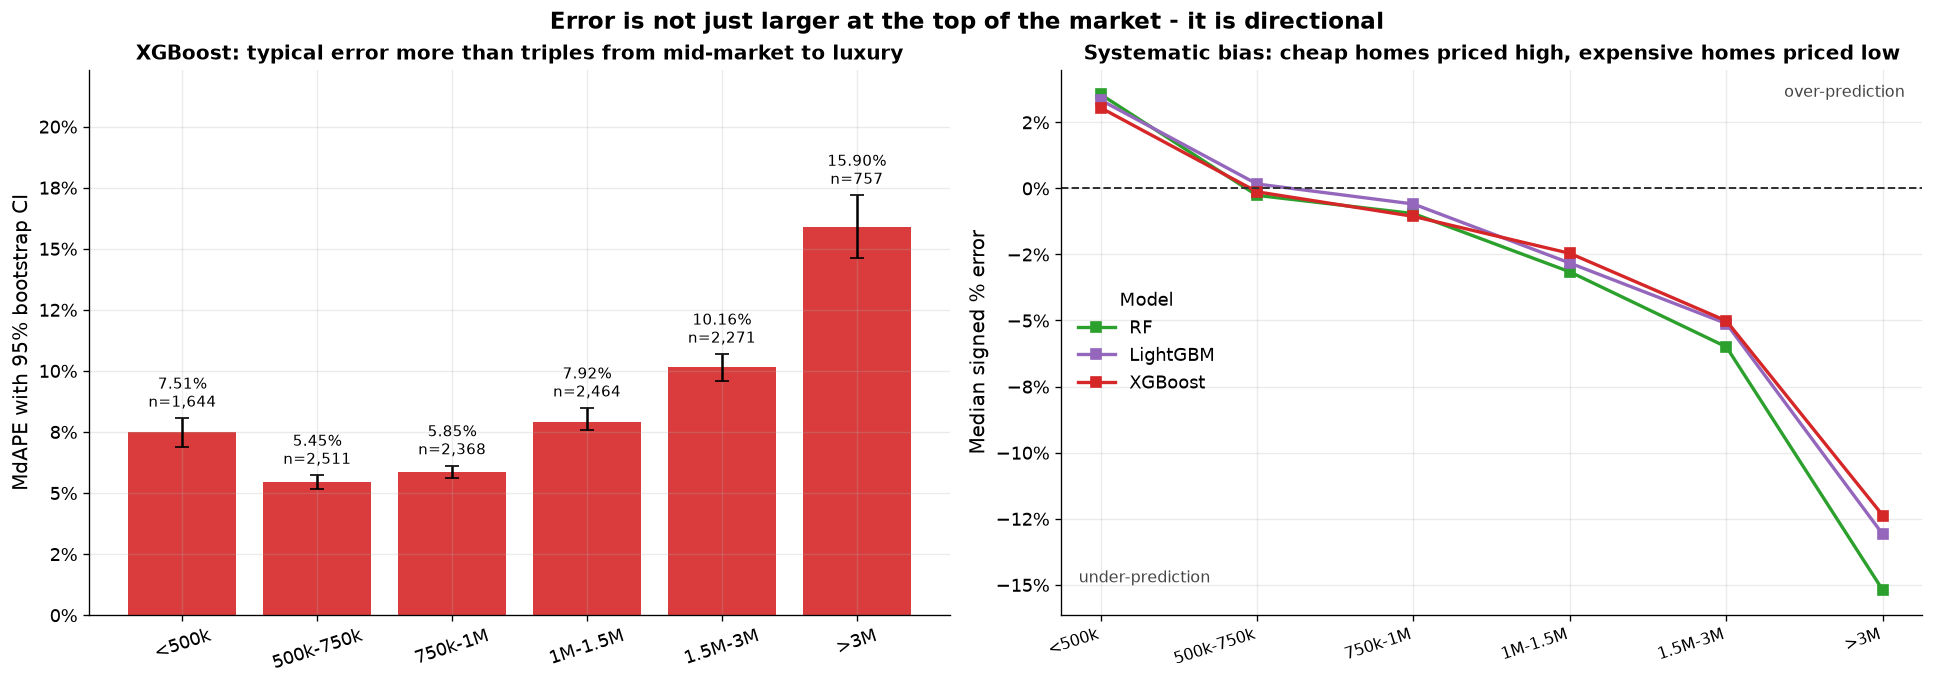

In [7]:
# Produces: Figure 3 - band error with confidence intervals, and the direction of the error
# Figure 3: directional bias by band + bootstrap CIs for the headline model (w8_fig3)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), constrained_layout=True)

s = band[band.scope.eq('fixed_band') & band.model.eq(HEADLINE)].sort_values('order')
labs = s['group'].tolist()
err = np.vstack([s['MdAPE'] * 100 - s['MdAPE_ci_lo_pct'], s['MdAPE_ci_hi_pct'] - s['MdAPE'] * 100])
axes[0].bar(labs, s['MdAPE'] * 100, yerr=err, capsize=4, color=ps.MODEL_COLORS[HEADLINE], alpha=0.9)
for i, (v, hi, n) in enumerate(zip(s['MdAPE'] * 100, s['MdAPE_ci_hi_pct'], s['n'])):
    axes[0].annotate(f'{v:.2f}%\nn={n:,}', (i, hi), xytext=(0, 7), textcoords='offset points',
                     ha='center', fontsize=9)   # anchored above the CI whisker, not the bar top
axes[0].yaxis.set_major_formatter(mt.PercentFormatter(xmax=100, decimals=0))
axes[0].set_ylabel('MdAPE with 95% bootstrap CI')
axes[0].set_ylim(0, s['MdAPE_ci_hi_pct'].max() * 1.3)
axes[0].set_title(f'{HEADLINE}: typical error more than triples from mid-market to luxury', fontsize=12)
axes[0].tick_params(axis='x', rotation=18)

for m in ['RF', 'LightGBM', HEADLINE]:
    sm = band[band.scope.eq('fixed_band') & band.model.eq(m)].sort_values('order')
    axes[1].plot(range(len(labs)), sm['median_signed_pct_error'], marker='s', lw=2,
                 color=ps.MODEL_COLORS[m], label=m)
axes[1].axhline(0, color='#333333', lw=1.2, ls='--')
axes[1].annotate('over-prediction', (0.98, 0.95), xycoords='axes fraction', ha='right',
                 fontsize=9.5, color='#444444')
axes[1].annotate('under-prediction', (0.02, 0.06), xycoords='axes fraction', fontsize=9.5, color='#444444')
axes[1].set_xticks(range(len(labs)))
axes[1].set_xticklabels(labs, rotation=18, ha='right', fontsize=9.5)
axes[1].yaxis.set_major_formatter(mt.PercentFormatter(xmax=100, decimals=0))
axes[1].set_ylabel('Median signed % error')
axes[1].set_title('Systematic bias: cheap homes priced high, expensive homes priced low', fontsize=12)
axes[1].legend(title='Model')
fig.suptitle('Error is not just larger at the top of the market - it is directional', fontsize=14, fontweight='bold')
print('saved:', ps.save(fig, 'w8_fig3_band_bias.png'))
plt.show()

### Step 8: Which gaps are real

**What this shows:** Each price band is compared against the best band by re-drawing the homes in both two thousand times, which gives a range for the difference. A range that includes zero is not treated as a real difference.

**Results:** 9 of 9 band comparisons are larger than this noise in May 2026, though the 750k-1M band clears it by only 0.02 points, which is treated as no real difference.

In [8]:
# Produces: the band-versus-band bootstrap contrasts and the written price-band finding
# Which band differences survive a bootstrap? (outputs/week8_band_contrasts.csv)
cv = contr.copy()
cv['95% CI of difference'] = [f'[{lo:+.2f}, {hi:+.2f}] pp' for lo, hi in
                              zip(cv['diff_ci_lo_pp'], cv['diff_ci_hi_pp'])]
display(Markdown(f'### 3d. Is band X really worse than the best band? ({HEADLINE}, 2,000-resample bootstrap)'))
display(cv[['scope', 'band', 'best_band', 'n_band', 'band_MdAPE_pct', 'best_band_MdAPE_pct',
            'diff_pp', '95% CI of difference', 'worse_than_best_beyond_noise']]
        .style.format({'band_MdAPE_pct': '{:.2f}%', 'best_band_MdAPE_pct': '{:.2f}%',
                       'diff_pp': '{:+.2f} pp', 'n_band': '{:,}'}).hide(axis='index'))

q = band[band.scope.eq('train_quintile') & band.model.eq(HEADLINE)].sort_values('order')
f = band[band.scope.eq('fixed_band') & band.model.eq(HEADLINE)].sort_values('order')
qb, qw = q.loc[q['MdAPE'].idxmin()], q.loc[q['MdAPE'].idxmax()]
fb, fw = f.loc[f['MdAPE'].idxmin()], f.loc[f['MdAPE'].idxmax()]
marginal = cv[(cv.diff_ci_lo_pp > 0) & (cv.diff_ci_lo_pp < 0.1)]
n_small = int(band['below_min_n'].sum())

display(Markdown(f'''
**Which price bands perform better, and why that is plausible.**

- The best segment is **{qb["group"]}** ({HEADLINE} MdAPE {qb["MdAPE"]:.2%}, 95% CI
  [{qb["MdAPE_ci_lo_pct"]:.2f}, {qb["MdAPE_ci_hi_pct"]:.2f}] pp, n = {int(qb["n"]):,}); the worst is
  **{qw["group"]}** ({qw["MdAPE"]:.2%}, CI [{qw["MdAPE_ci_lo_pct"]:.2f}, {qw["MdAPE_ci_hi_pct"]:.2f}] pp,
  n = {int(qw["n"]):,}). The gap is **{100*(qw["MdAPE"] - qb["MdAPE"]):.2f} pp**, far outside either interval.
  On fixed bands the same pattern holds: {fb["group"]} at {fb["MdAPE"]:.2%} versus {fw["group"]} at
  {fw["MdAPE"]:.2%} (n = {int(fw["n"]):,}).
- **Every** band in the contrast table is worse than the best band by more than bootstrap noise
  ({int(cv["worse_than_best_beyond_noise"].sum())} of {len(cv)} contrasts exclude zero)
  {"- though " + ", ".join(f"`{r.band}` (CI lower bound {r.diff_ci_lo_pp:+.2f} pp)" for r in marginal.itertuples()) + " only barely does, and should be read as 'no material difference'" if len(marginal) else ""}.
- **Why this is plausible.** Mid-market homes ({fb["group"]}, median sale {usd(fb["median_actual_price"])})
  are the densest part of the training data and the most standardised: similar tract housing, many
  comparable sales per ZIP, value driven by square footage and location in a way the features capture.
  The top band ({fw["group"]}, median sale {usd(fw["median_actual_price"])}) is thin
  ({fw["pct_of_test"]:.1f}% of test homes), heterogeneous, and its value depends on view, finish quality,
  architect, privacy and lot shape - none of which are in the feature set. The bottom band
  ({f.iloc[0]["group"]}) is also worse than mid-market ({f.iloc[0]["MdAPE"]:.2%}): a percentage error is
  mechanically easier to incur on a small denominator, and that segment mixes distressed, rural and
  manufactured-adjacent stock.
- **Directional bias** runs monotonically from {f.iloc[0]["median_signed_pct_error"]:+.2f}% in
  {f.iloc[0]["group"]} to {fw["median_signed_pct_error"]:+.2f}% in {fw["group"]}. This is regression to the
  mean plus the hard training price cap ({usd(TRAIN_CAP)}, learned on train only): tree models
  cannot predict above the most expensive homes they were trained on, so luxury sales are systematically
  under-priced.
- Groups flagged below n = {MIN_N}: **{n_small}** (none of the band conclusions above rests on a small group).
'''))

### 3d. Is band X really worse than the best band? (XGBoost, 2,000-resample bootstrap)

scope,band,best_band,n_band,band_MdAPE_pct,best_band_MdAPE_pct,diff_pp,95% CI of difference,worse_than_best_beyond_noise
train_quintile,Q1 <575k,Q2 575-785k,"2,333",6.63%,5.33%,+1.30 pp,"[+0.83, +1.81] pp",True
train_quintile,"Q3 785-1,050k",Q2 575-785k,"2,225",6.02%,5.33%,+0.69 pp,"[+0.26, +1.10] pp",True
train_quintile,"Q4 1,050k-1.59M",Q2 575-785k,"2,548",8.08%,5.33%,+2.75 pp,"[+2.18, +3.31] pp",True
train_quintile,Q5 >1.59M,Q2 575-785k,"2,704",11.60%,5.33%,+6.27 pp,"[+5.64, +6.95] pp",True
fixed_band,<500k,500k-750k,"1,644",7.51%,5.45%,+2.07 pp,"[+1.43, +2.66] pp",True
fixed_band,750k-1M,500k-750k,"2,368",5.85%,5.45%,+0.40 pp,"[+0.02, +0.78] pp",True
fixed_band,1M-1.5M,500k-750k,"2,464",7.92%,5.45%,+2.48 pp,"[+2.03, +3.12] pp",True
fixed_band,1.5M-3M,500k-750k,"2,271",10.16%,5.45%,+4.71 pp,"[+4.05, +5.34] pp",True
fixed_band,>3M,500k-750k,757,15.90%,5.45%,+10.46 pp,"[+9.24, +11.73] pp",True



**Which price bands perform better, and why that is plausible.**

- The best segment is **Q2 575-785k** (XGBoost MdAPE 5.33%, 95% CI
  [5.06, 5.67] pp, n = 2,205); the worst is
  **Q5 >1.59M** (11.60%, CI [11.07, 12.18] pp,
  n = 2,704). The gap is **6.27 pp**, far outside either interval.
  On fixed bands the same pattern holds: 500k-750k at 5.45% versus >3M at
  15.90% (n = 757).
- **Every** band in the contrast table is worse than the best band by more than bootstrap noise
  (9 of 9 contrasts exclude zero)
  - though `750k-1M` (CI lower bound +0.02 pp) only barely does, and should be read as 'no material difference'.
- **Why this is plausible.** Mid-market homes (500k-750k, median sale $626,000)
  are the densest part of the training data and the most standardised: similar tract housing, many
  comparable sales per ZIP, value driven by square footage and location in a way the features capture.
  The top band (>3M, median sale $4,050,000) is thin
  (6.3% of test homes), heterogeneous, and its value depends on view, finish quality,
  architect, privacy and lot shape - none of which are in the feature set. The bottom band
  (<500k) is also worse than mid-market (7.51%): a percentage error is
  mechanically easier to incur on a small denominator, and that segment mixes distressed, rural and
  manufactured-adjacent stock.
- **Directional bias** runs monotonically from +3.05% in
  <500k to -12.38% in >3M. This is regression to the
  mean plus the hard training price cap ($8,900,000, learned on train only): tree models
  cannot predict above the most expensive homes they were trained on, so luxury sales are systematically
  under-priced.
- Groups flagged below n = 200: **0** (none of the band conclusions above rests on a small group).


### Step 9: Accuracy by county

**What this shows:** The same errors grouped by county, which comes from the school-district boundary each home falls inside. Counties with fewer than 200 sales this month are pooled into one labelled row rather than dropped, so nothing is hidden.

**Results:** In May 2026 the most accurate county is Riverside at 5.63% and the hardest is Alameda at 10.17%.

In [9]:
# Produces: two county tables: XGBoost in detail, then MdAPE for all five models
cv = county[county.model.eq(HEADLINE)].sort_values('n', ascending=False).copy()
cv['MdAPE_95CI'] = [f'[{lo:.2f}, {hi:.2f}] pp' for lo, hi in zip(cv['MdAPE_ci_lo_pct'], cv['MdAPE_ci_hi_pct'])]
display(Markdown(f'### 4a. County-level error - {HEADLINE}'))
display(cv[['group', 'n', 'pct_of_test', 'median_actual_price', 'MdAPE', 'MdAPE_95CI',
            'median_signed_pct_error', 'MAE', 'MAPE', 'below_min_n']]
        .style.format(FMT).background_gradient(subset=['MdAPE'], cmap='RdYlGn_r').hide(axis='index'))

display(Markdown('### 4a (cont.) MdAPE by county, all five models'))
cp = (county.pivot_table(index=['group', 'n'], columns='model', values='MdAPE')
      .reset_index().sort_values('n', ascending=False))
display(cp[['group', 'n'] + MODELS].style.format({m: '{:.2%}' for m in MODELS} | {'n': '{:,}'})
        .background_gradient(subset=MODELS, cmap='RdYlGn_r', axis=None).hide(axis='index'))

### 4a. County-level error - XGBoost

group,n,pct_of_test,median_actual_price,MdAPE,MdAPE_95CI,median_signed_pct_error,MAE,MAPE,below_min_n
Los Angeles,"2,922",24.3%,"$1,056,825",8.34%,"[7.97, 8.64] pp",-1.65%,"$246,666",12.97%,False
Riverside,"1,796",14.9%,"$635,000",5.63%,"[5.31, 5.88] pp",-0.71%,"$92,840",10.08%,False
"Other (43 counties, each n<200)","1,386",11.5%,"$585,000",8.21%,"[7.48, 8.91] pp",-0.24%,"$147,631",16.09%,False
San Diego,"1,311",10.9%,"$1,090,000",7.69%,"[7.15, 8.24] pp",-1.76%,"$314,006",11.35%,False
San Bernardino,"1,189",9.9%,"$550,000",5.82%,"[5.36, 6.33] pp",-0.79%,"$56,324",13.43%,False
Orange,"1,176",9.8%,"$1,472,500",7.24%,"[6.88, 7.85] pp",-2.83%,"$291,147",44.62%,False
Alameda,611,5.1%,"$1,400,000",10.17%,"[9.09, 11.02] pp",-2.71%,"$224,885",14.30%,False
Contra Costa,597,5.0%,"$970,000",7.04%,"[6.18, 7.87] pp",-2.00%,"$184,344",10.74%,False
Santa Clara,414,3.4%,"$1,964,000",9.82%,"[8.71, 10.90] pp",-0.64%,"$312,555",12.09%,False
Ventura,410,3.4%,"$1,025,000",6.75%,"[6.06, 7.63] pp",-2.15%,"$154,809",9.53%,False


### 4a (cont.) MdAPE by county, all five models

group,n,LR,DT,RF,LightGBM,XGBoost
Los Angeles,"2,922",10.18%,11.46%,9.49%,8.34%,8.34%
Riverside,"1,796",8.82%,8.05%,6.18%,5.81%,5.63%
"Other (43 counties, each n<200)","1,386",10.28%,12.42%,9.04%,8.08%,8.21%
San Diego,"1,311",9.52%,10.43%,8.59%,7.53%,7.69%
San Bernardino,"1,189",7.78%,8.54%,6.32%,5.21%,5.82%
Orange,"1,176",9.67%,10.50%,8.41%,7.72%,7.24%
Alameda,611,12.01%,11.62%,9.84%,9.39%,10.17%
Contra Costa,597,9.24%,9.48%,7.64%,7.10%,7.04%
Santa Clara,414,11.39%,12.61%,10.26%,10.26%,9.82%
Ventura,410,8.31%,9.50%,7.68%,6.79%,6.75%


### Step 10: The county chart with uncertainty

**What this shows:** One bar per county, ordered from most to least accurate, each with a whisker showing how far its figure could move given how few sales it rests on. The grey bar pools the small counties.

**Results:** The 10 counties with enough sales cover 88.5 percent of May 2026, and the remaining 43 sit in the grey bar. Where whiskers overlap, those counties cannot be ranked against each other.

saved: outputs/figures/w8_fig4_mdape_by_county.png


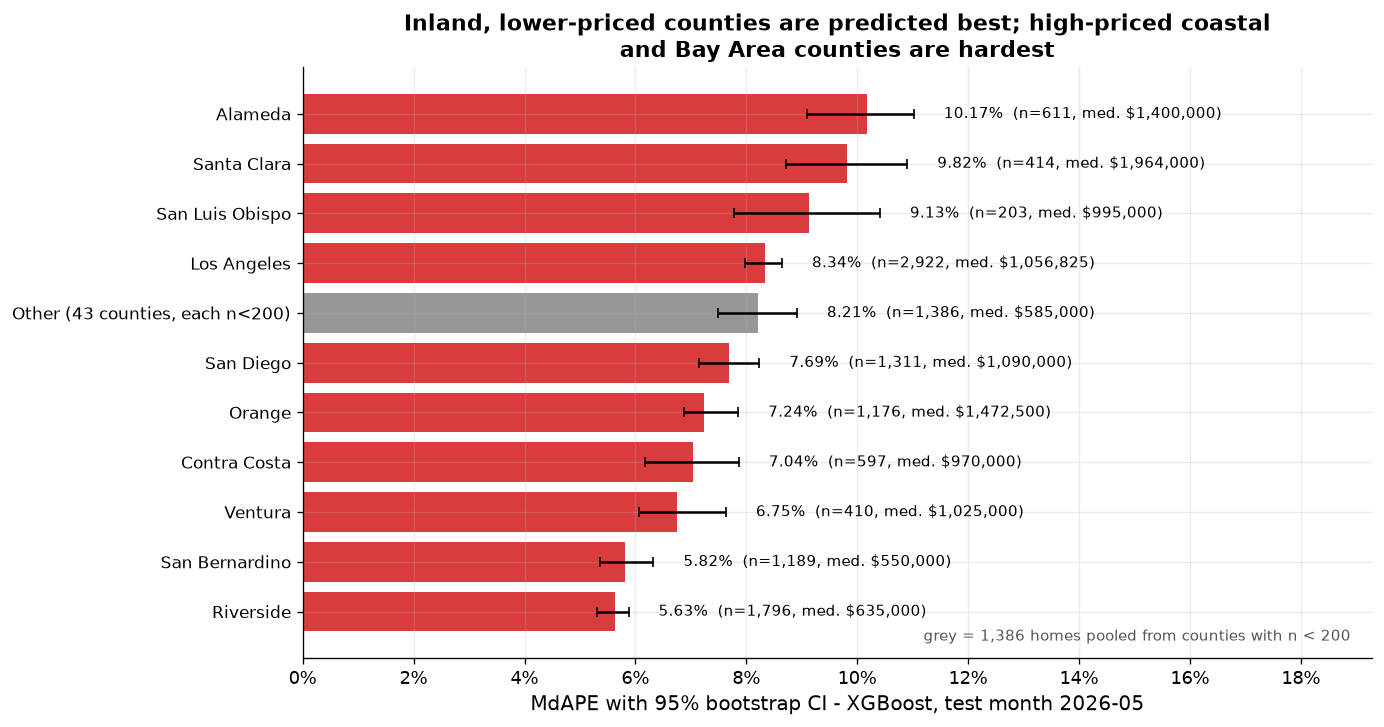

In [10]:
# Produces: Figure 4 - county MdAPE with 95% confidence intervals and counts
# Figure 4: county MdAPE with CIs and counts (w8_fig4)
cs = county[county.model.eq(HEADLINE)].sort_values('MdAPE')
fig, ax = plt.subplots(figsize=(11.5, 6.4))
err = np.vstack([cs['MdAPE'] * 100 - cs['MdAPE_ci_lo_pct'], cs['MdAPE_ci_hi_pct'] - cs['MdAPE'] * 100])
cols = ['#8c8c8c' if 'Other' in g else ps.MODEL_COLORS[HEADLINE] for g in cs['group']]
b = ax.barh(range(len(cs)), cs['MdAPE'] * 100, xerr=err, capsize=3, color=cols, alpha=0.9)
ax.set_yticks(range(len(cs)))
ax.set_yticklabels(cs['group'], fontsize=10)
ax.bar_label(b, labels=[f'{v:.2f}%  (n={n:,}, med. {usd(p)})' for v, n, p in
                        zip(cs['MdAPE'] * 100, cs['n'], cs['median_actual_price'])],
             fontsize=9, padding=18)
ax.set_xlim(0, cs['MdAPE_ci_hi_pct'].max() * 1.75)
ax.xaxis.set_major_locator(mt.MultipleLocator(2))   # avoid 2.5 -> "2%", 7.5 -> "8%" tick rounding
ax.xaxis.set_major_formatter(mt.PercentFormatter(xmax=100, decimals=0))
ax.set_xlabel(f'MdAPE with 95% bootstrap CI - {HEADLINE}, test month 2026-05')
ax.set_title('Inland, lower-priced counties are predicted best; high-priced coastal\n'
             'and Bay Area counties are hardest', fontsize=13)
ax.annotate(f'grey = {int(county[county.group.str.contains("Other")]["n"].iloc[0]):,} homes pooled from '
            f'counties with n < {MIN_N}', (0.98, 0.03), xycoords='axes fraction', ha='right', fontsize=9,
            color='#555555')
print('saved:', ps.save(fig, 'w8_fig4_mdape_by_county.png'))
plt.show()

### Step 11: Why the breakdown stops at county

**What this shows:** The same breakdown attempted at ZIP code level, which is the unit an agent would really want, with the number of sales behind every row shown.

**Results:** May 2026's sales spread over 1,073 ZIP codes and the largest holds only 74 of them, so no ZIP reaches the 200-sale minimum. County is the finest level this single month can support.

In [11]:
# Produces: the ZIP-code table and the written geography finding
display(Markdown('### 4b. ZIP code: reported for transparency, not usable for conclusions'))
zv = zips[zips.model.eq(HEADLINE)].sort_values('n', ascending=False).copy()
zv['MdAPE_95CI'] = [f'[{lo:.2f}, {hi:.2f}] pp' for lo, hi in zip(zv['MdAPE_ci_lo_pct'], zv['MdAPE_ci_hi_pct'])]
display(zv[['group', 'n', 'median_actual_price', 'MdAPE', 'MdAPE_95CI',
            'median_signed_pct_error', 'below_min_n']].rename(columns={'group': 'ZIP'})
        .style.format(FMT | {'n': '{:,}'}).hide(axis='index'))

n_zip = test['PostalCode'].nunique()
zc = test['PostalCode'].value_counts()
big_c = county[county.model.eq(HEADLINE) & ~county.group.str.contains('Other')].sort_values('MdAPE')
cbest, cwors = big_c.iloc[0], big_c.iloc[-1]
overlap = cbest['MdAPE_ci_hi_pct'] >= cwors['MdAPE_ci_lo_pct']
import re
_other_lbl = county[county.group.str.contains('Other')]['group'].iloc[0]
n_cty_small = int(county[county.group.str.contains('Other')]['n'].iloc[0])
n_cty_pooled = int(re.search(r'\((\d+) counties', _other_lbl).group(1))

display(Markdown(f'''
The test month spreads {len(test):,} sales over **{n_zip:,} ZIP codes**; the largest holds
**{int(zc.iloc[0])}** sales and **{int((zc >= MIN_N).sum())}** reach the n = {MIN_N} minimum. Every row above is
therefore flagged: with n in the tens, a ZIP's MdAPE CI spans several percentage points and ZIP-level
rankings would be noise. ZIP is used *inside* the models as a feature (where the training window gives it
far more support), but it is not a reportable reporting unit here. County is the finest geography this
test month can support.

**Which geographies perform better, and why that is plausible.**

- Best: **{cbest["group"]}** ({cbest["MdAPE"]:.2%}, CI [{cbest["MdAPE_ci_lo_pct"]:.2f}, {cbest["MdAPE_ci_hi_pct"]:.2f}] pp,
  n = {int(cbest["n"]):,}, median sale {usd(cbest["median_actual_price"])}).
  Worst: **{cwors["group"]}** ({cwors["MdAPE"]:.2%}, CI [{cwors["MdAPE_ci_lo_pct"]:.2f}, {cwors["MdAPE_ci_hi_pct"]:.2f}] pp,
  n = {int(cwors["n"]):,}, median sale {usd(cwors["median_actual_price"])}).
  The two intervals {"overlap, so this ordering is not firm" if overlap else "do not overlap, so the ordering is firm at the ends"};
  neighbouring counties in the middle of the table *do* overlap and should not be ranked against each other.
- The pattern tracks price level and housing homogeneity, not geography as such: the best counties are
  inland and lower-priced with large volumes of similar tract housing, while the hardest are expensive
  coastal and Bay Area markets where lot, view and micro-location dominate value. This is the same effect
  as the price-band table seen through a geographic lens, which is why county error correlates with county
  median sale price.
- {n_cty_small:,} test homes ({100*n_cty_small/len(test):.1f}%) sit in the {n_cty_pooled} pooled
  small counties; they are reported as one row, never dropped, and the AVM should be treated as unvalidated
  in those markets individually.
'''))

### 4b. ZIP code: reported for transparency, not usable for conclusions

ZIP,n,median_actual_price,MdAPE,MdAPE_95CI,median_signed_pct_error,below_min_n
92596,74,"$629,925",2.72%,"[1.97, 3.49] pp",-0.98%,True
92592,73,"$774,900",4.89%,"[3.99, 6.63] pp",-1.16%,True
92345,69,"$475,000",4.27%,"[2.47, 5.57] pp",-0.54%,True
92253,68,"$866,250",12.42%,"[7.63, 19.85] pp",+3.12%,True
92584,66,"$640,000",4.61%,"[3.35, 6.26] pp",-2.61%,True
92223,59,"$558,000",4.14%,"[3.12, 5.34] pp",-2.75%,True
92211,59,"$588,000",11.09%,"[7.77, 15.36] pp",+2.94%,True
92562,56,"$675,000",4.69%,"[3.06, 5.87] pp",-1.34%,True
94513,54,"$779,500",5.43%,"[3.83, 7.28] pp",+1.54%,True
93536,53,"$550,000",5.60%,"[3.65, 8.49] pp",+1.77%,True



The test month spreads 12,015 sales over **1,073 ZIP codes**; the largest holds
**74** sales and **0** reach the n = 200 minimum. Every row above is
therefore flagged: with n in the tens, a ZIP's MdAPE CI spans several percentage points and ZIP-level
rankings would be noise. ZIP is used *inside* the models as a feature (where the training window gives it
far more support), but it is not a reportable reporting unit here. County is the finest geography this
test month can support.

**Which geographies perform better, and why that is plausible.**

- Best: **Riverside** (5.63%, CI [5.31, 5.88] pp,
  n = 1,796, median sale $635,000).
  Worst: **Alameda** (10.17%, CI [9.09, 11.02] pp,
  n = 611, median sale $1,400,000).
  The two intervals do not overlap, so the ordering is firm at the ends;
  neighbouring counties in the middle of the table *do* overlap and should not be ranked against each other.
- The pattern tracks price level and housing homogeneity, not geography as such: the best counties are
  inland and lower-priced with large volumes of similar tract housing, while the hardest are expensive
  coastal and Bay Area markets where lot, view and micro-location dominate value. This is the same effect
  as the price-band table seen through a geographic lens, which is why county error correlates with county
  median sale price.
- 1,386 test homes (11.5%) sit in the 43 pooled
  small counties; they are reported as one row, never dropped, and the AVM should be treated as unvalidated
  in those markets individually.


### Step 12: Re-run at three earlier months

**What this shows:** The five models are rebuilt at three earlier points in time, each trained only on the twelve months before it and scored on the month that follows. The settings are frozen from Week 7 rather than re-tuned, so this tests whether one fixed configuration holds up.

**Results:** XGBoost's typical error stays between 7.45% and 7.64% on 2025-11 and 2026-02, against 7.38% in May 2026. The 2026-04 month is the one the settings were tuned on, so it flatters every model.

In [12]:
# Produces: the backtest window sizes, MdAPE and MAE by cutoff, and the booster tree counts
bk = back.copy()
cuts = sorted(bk['cutoff'].unique())
bk['label'] = bk['cutoff'] + np.where(bk['is_tuning_month'], ' (tuning month)',
                                      np.where(bk['cutoff'].eq('2026-05'), ' (held-out test)', ''))
piv_md = (bk.pivot_table(index=['cutoff', 'label'], columns='model', values='MdAPE')
          .reset_index().sort_values('cutoff'))
piv_mae = (bk.pivot_table(index=['cutoff', 'label'], columns='model', values='MAE')
           .reset_index().sort_values('cutoff'))
sizes = (bk[bk.model.eq(HEADLINE)][['cutoff', 'train_start', 'train_end', 'n_train', 'n_test']]
         .sort_values('cutoff'))

display(Markdown('### 5a. Window sizes'))
display(sizes.style.format({'n_train': '{:,.0f}', 'n_test': '{:,.0f}'}).hide(axis='index'))
display(Markdown('### 5b. MdAPE by cutoff'))
display(piv_md[['label'] + MODELS].style.format({m: '{:.2%}' for m in MODELS})
        .background_gradient(subset=MODELS, cmap='RdYlGn_r', axis=None).hide(axis='index'))
display(Markdown('### 5c. MAE by cutoff'))
display(piv_mae[['label'] + MODELS].style.format({m: '${:,.0f}' for m in MODELS}).hide(axis='index'))

display(Markdown('### 5d. Booster tree counts actually used (iteration-scaling rule applied per window)'))
it = (bk[bk.model.isin(['LightGBM', 'XGBoost'])]
      .pivot_table(index=['cutoff', 'n_train'], columns='model', values='n_estimators')
      .reset_index().sort_values('cutoff'))
display(it.style.format({'n_train': '{:,.0f}', 'LightGBM': '{:,.0f}', 'XGBoost': '{:,.0f}'}).hide(axis='index'))

### 5a. Window sizes

cutoff,train_start,train_end,n_train,n_test
2025-11,2024-11,2025-10,"129,253","9,732"
2026-02,2025-02,2026-01,"127,471","8,545"
2026-04,2025-04,2026-03,"127,734","12,021"
2026-05,2025-05,2026-04,"127,939","12,015"


### 5b. MdAPE by cutoff

label,LR,DT,RF,LightGBM,XGBoost
2025-11,9.67%,9.99%,7.86%,7.53%,7.45%
2026-02,10.03%,10.32%,8.26%,7.71%,7.64%
2026-04 (tuning month),9.62%,10.39%,8.16%,7.58%,7.58%
2026-05 (held-out test),9.58%,10.32%,8.19%,7.40%,7.38%


### 5c. MAE by cutoff

label,LR,DT,RF,LightGBM,XGBoost
2025-11,"$305,951","$340,998","$302,049","$282,358","$280,525"
2026-02,"$366,679","$390,096","$352,698","$339,581","$335,943"
2026-04 (tuning month),"$416,710","$443,501","$407,159","$387,036","$387,001"
2026-05 (held-out test),"$228,645","$256,543","$220,621","$198,928","$198,830"


### 5d. Booster tree counts actually used (iteration-scaling rule applied per window)

cutoff,n_train,LightGBM,XGBoost
2025-11,"129,253","2,022","1,032"
2026-02,"127,471","1,994","1,018"
2026-04,"127,734","1,998","1,020"
2026-05,"127,939","2,001","1,022"


### Step 13: Why R-squared collapses some months

**What this shows:** For each scored month, the share of the total price variation held by just its three largest sales, shown next to that month's R-squared and errors.

**Results:** In 2026-02 the top three sales alone hold 98.4% of the variation, and no model's R-squared that month rises above 0.0110. Those prices are almost certainly data-entry errors, so only the percent-error measures can be compared across months.

In [13]:
# Produces: the table of extreme sales showing why R2 is not comparable across months
# Why R2/RMSE/MAE are NOT comparable across scored months: a few extreme sales dominate them.
ext = pd.read_csv('outputs/08_features_backtest.csv', usecols=['Month', 'ClosePrice'])
rows = []
for c in cuts:
    y = ext.loc[ext['Month'].eq(c), 'ClosePrice'].to_numpy(float)
    sq = (y - y.mean()) ** 2
    rows.append({'scored month': c, 'n': len(y), 'max sale': y.max(),
                 'sales > $20M': int((y > 2e7).sum()),
                 'share of SST held by top 3 sales': np.sort(sq)[-3:].sum() / sq.sum(),
                 f'{HEADLINE} R2': bk[bk.cutoff.eq(c) & bk.model.eq(HEADLINE)]['R2'].iloc[0],
                 f'{HEADLINE} MAE': bk[bk.cutoff.eq(c) & bk.model.eq(HEADLINE)]['MAE'].iloc[0],
                 f'{HEADLINE} MdAPE': bk[bk.cutoff.eq(c) & bk.model.eq(HEADLINE)]['MdAPE'].iloc[0]})
ext_tab = pd.DataFrame(rows)
display(Markdown('### 5e. Why only MdAPE/MAPE are comparable across months'))
display(ext_tab.style.format({'n': '{:,}', 'max sale': '${:,.0f}', 'sales > $20M': '{:,}',
                              'share of SST held by top 3 sales': '{:.1%}',
                              f'{HEADLINE} R2': '{:.4f}', f'{HEADLINE} MAE': '${:,.0f}',
                              f'{HEADLINE} MdAPE': '{:.2%}'}).hide(axis='index'))

### 5e. Why only MdAPE/MAPE are comparable across months

scored month,n,max sale,sales > $20M,share of SST held by top 3 sales,XGBoost R2,XGBoost MAE,XGBoost MdAPE
2025-11,"9,732","$740,000,000",6,97.1%,0.0217,"$280,525",7.45%
2026-02,"8,545","$699,000,000",5,98.4%,0.0107,"$335,943",7.64%
2026-04,"12,021","$796,000,000",11,98.3%,0.0093,"$387,001",7.58%
2026-05,"12,015","$97,972,500",9,37.7%,0.4934,"$198,830",7.38%


### Step 14: Does accuracy hold over time

**What this shows:** Typical percent error by scored month on the left, average dollar error on the right, one line per model. Flat lines mean accuracy that does not depend on which month was chosen.

**Results:** Across all 4 scored months the two gradient-boosting models take the top two places and the other three keep the same order below them, and XGBoost's typical error moves only about 0.19 points between 2025-11 and 2026-02.

saved: outputs/figures/w8_fig5_rolling_origin_backtest.png


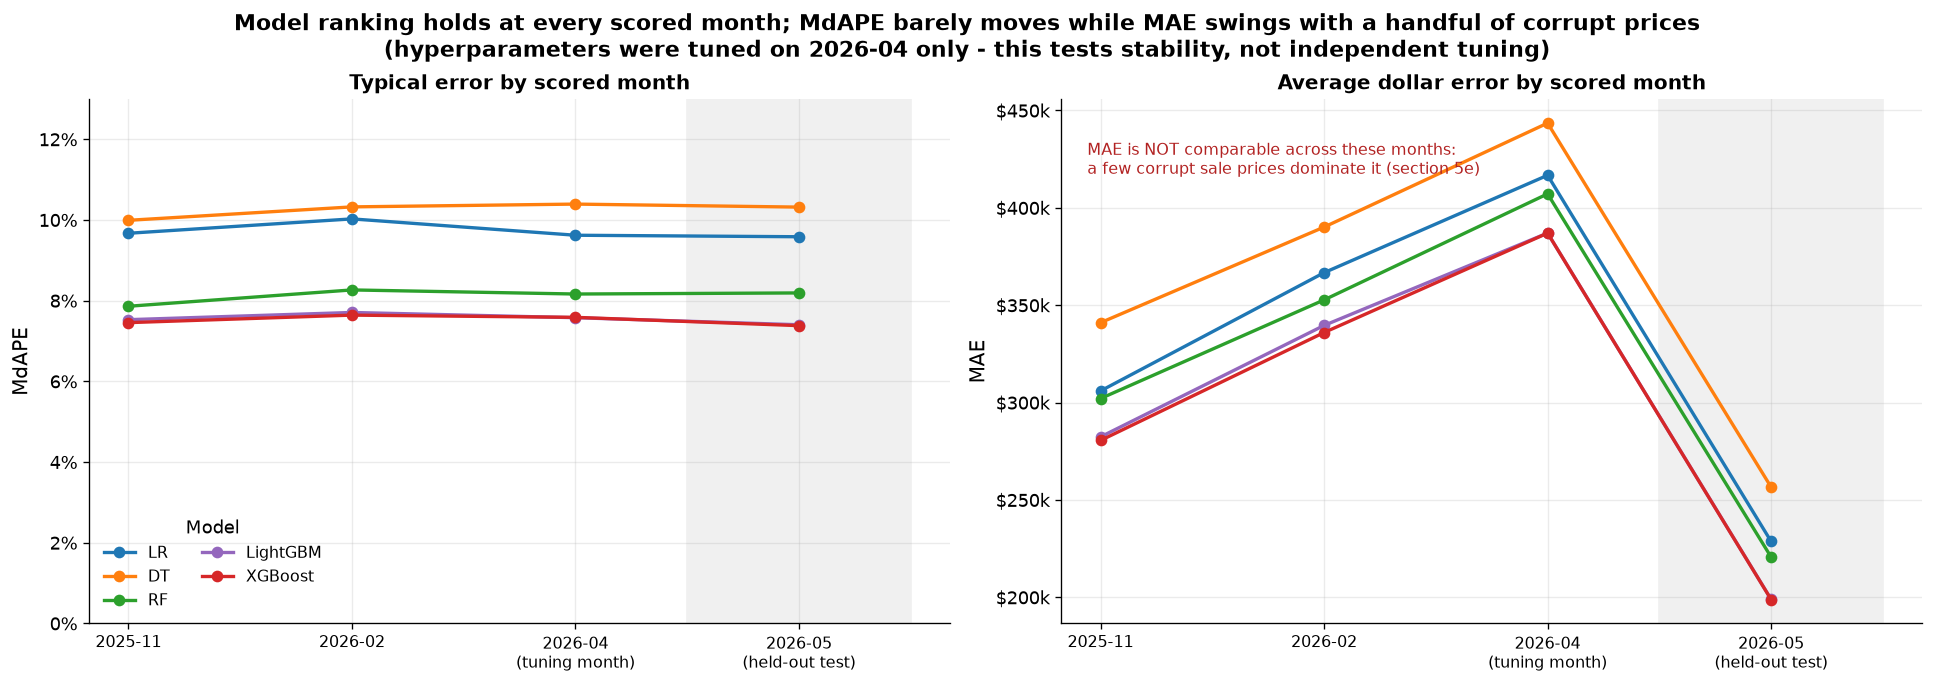

In [14]:
# Produces: Figure 5 - MdAPE and MAE across the four scored months
# Figure 5: stability over time (w8_fig5)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), constrained_layout=True)
cuts = sorted(bk['cutoff'].unique())
for ax, col, ylab, fmtr, title in [
    (axes[0], 'MdAPE', 'MdAPE', mt.PercentFormatter(xmax=1, decimals=0), 'Typical error by scored month'),
    (axes[1], 'MAE', 'MAE', ps.usd, 'Average dollar error by scored month')]:
    for m in MODELS:
        sm = bk[bk.model.eq(m)].set_index('cutoff').reindex(cuts)
        ax.plot(range(len(cuts)), sm[col], marker='o', lw=2, ms=6, color=ps.MODEL_COLORS[m], label=m)
    ax.set_xticks(range(len(cuts)))
    ax.set_xticklabels([c + ('\n(tuning month)' if c == '2026-04' else '\n(held-out test)' if c == '2026-05' else '')
                        for c in cuts], fontsize=9.5)
    ax.axvspan(len(cuts) - 1.5, len(cuts) - 0.5, color='#f0f0f0', zorder=0)
    ax.yaxis.set_major_formatter(fmtr)
    ax.set_ylabel(ylab)
    ax.set_title(title, fontsize=12)
axes[0].legend(title='Model', ncols=2, fontsize=9.5)
axes[0].set_ylim(0, bk['MdAPE'].max() * 1.25)
axes[1].annotate('MAE is NOT comparable across these months:\na few corrupt sale prices dominate it (section 5e)',
                 (0.03, 0.92), xycoords='axes fraction', fontsize=9.5, color='#b22222', va='top')
fig.suptitle('Model ranking holds at every scored month; MdAPE barely moves while MAE swings with a '
             'handful of corrupt prices\n(hyperparameters were tuned on 2026-04 only - this tests '
             'stability, not independent tuning)', fontsize=13, fontweight='bold')
print('saved:', ps.save(fig, 'w8_fig5_rolling_origin_backtest.png'))
plt.show()

### Step 15: What the time test shows

**What this shows:** The written version of the result above, generated from the same table so the words cannot drift away from the numbers. It separates what is stable from what is not.

**Results:** LightGBM and XGBoost hold the top two places in all 4 scored months, so last week's ranking was not a one-month accident. Dollar errors are not comparable across those months, and the 2026-04 month is excluded from the stability range because it is the month the settings came from.

In [15]:
# Produces: the written backtest finding: what is stable and what is not
earlier = bk[~bk.cutoff.isin(['2026-04', '2026-05'])]
tune = bk[bk.cutoff.eq('2026-04')]
held = bk[bk.cutoff.eq('2026-05')]

lines = []
for m in MODELS:
    e = earlier[earlier.model.eq(m)]['MdAPE']
    lines.append(f'| {m} | ' + ' | '.join(f'{bk[bk.model.eq(m) & bk.cutoff.eq(c)]["MdAPE"].iloc[0]:.2%}'
                                          for c in cuts) +
                 f' | {100*(bk[bk.model.eq(m)]["MdAPE"].max() - bk[bk.model.eq(m)]["MdAPE"].min()):.2f} pp |')

rank_per_cut = {c: bk[bk.cutoff.eq(c)].sort_values('MdAPE')['model'].tolist() for c in cuts}
same_winner = len({r[0] for r in rank_per_cut.values()}) == 1
booster_top2 = all(set(r[:2]) == {'LightGBM', 'XGBoost'} for r in rank_per_cut.values())
h_tune = tune[tune.model.eq(HEADLINE)]['MdAPE'].iloc[0]
h_held = held[held.model.eq(HEADLINE)]['MdAPE'].iloc[0]
h_earl = earlier[earlier.model.eq(HEADLINE)]['MdAPE']
lgbm_cap = bk[bk.model.eq('LightGBM')]['n_estimators']

display(Markdown(f'''
### 5f. What the backtest shows

| Model | ''' + ' | '.join(cuts) + f''' | spread |
|---|''' + '---|' * (len(cuts) + 1) + '\n' + '\n'.join(lines) + f'''

- **The ranking is stable where it matters.**
  {"The two boosters hold the top two places at every scored month" if booster_top2 else "The top two places change across months"}, with
  RF third, LR fourth and DT last at {sum(1 for c in cuts if rank_per_cut[c][2:] == ["RF", "LR", "DT"])} of {len(cuts)} months.
  {HEADLINE} has the lowest MdAPE at {sum(1 for c in cuts if rank_per_cut[c][0] == HEADLINE)} of {len(cuts)} months;
  {"LightGBM takes it at " + ", ".join(c for c in cuts if rank_per_cut[c][0] != HEADLINE) + ", where Week 7's paired bootstrap already showed the two boosters are statistically tied (CI -0.15 to +0.13 pp), so that flip is noise, not a change of regime" if not same_winner else "no month reverses that"}.
  The Weeks 6-7 conclusion - boosters beat RF, which beats LR and DT on typical error - holds at every month
  tested, not only on 2026-05.
- **Absolute error moves month to month, but modestly.** {HEADLINE} ranges from {h_earl.min():.2%} to {h_earl.max():.2%} on the two
  genuinely out-of-sample earlier cutoffs, versus {h_tune:.2%} on the tuning month and {h_held:.2%} on the
  held-out test month. A single month's MdAPE should be quoted with that month-to-month variation attached.
- **Do not compare R2, RMSE or MAE across these months (section 5e).** Three of the four scored months contain
  extreme sales that are almost certainly data-entry errors: the largest single sale is
  {usd(ext_tab['max sale'].max())}, and in the worst month the top three sales alone hold
  {ext_tab['share of SST held by top 3 sales'].max():.1%} of the total sum of squares. Across the backtest
  cutoffs {HEADLINE}'s R2 falls as low as {ext_tab[f'{HEADLINE} R2'].min():.4f}. MAE moves the same way: it is
  {ext_tab[f'{HEADLINE} MAE'].max()/ext_tab[f'{HEADLINE} MAE'].min():.1f}x higher in the worst month than in
  2026-05 while MdAPE barely moves. Those months are not harder in any practical sense - they contain a handful
  of corrupt prices. **MdAPE and MAPE are the only cross-month-comparable metrics here**, which is the whole
  reason this project leads with MdAPE.
- **The 2026-04 cutoff is optimistic by construction** and is excluded from the stability range above: its
  hyperparameters and tree counts were selected on exactly those rows. It is shown for completeness only.
- **Caveat that applies to every row:** hyperparameters were tuned once, on 2026-04. Earlier cutoffs run a
  configuration chosen with knowledge of a *later* month. That direction of information flow does not leak the
  scored month's labels, but it does mean these numbers are not what an honest "what would have been deployed in
  2025-11" exercise would have produced - they test stability, not independent tuning.
- **LightGBM is still near its tree cap.** The scaled counts used here are
  {", ".join(f"{int(v):,}" for v in lgbm_cap.unique())}, derived from a validation fit that stopped at 1,998 of a
  2,000-tree cap. The cap was never lifted, so LightGBM may be undertrained at every cutoff and its backtest
  numbers are a lower bound on what it could do.
'''))


### 5f. What the backtest shows

| Model | 2025-11 | 2026-02 | 2026-04 | 2026-05 | spread |
|---|---|---|---|---|---|
| LR | 9.67% | 10.03% | 9.62% | 9.58% | 0.44 pp |
| DT | 9.99% | 10.32% | 10.39% | 10.32% | 0.40 pp |
| RF | 7.86% | 8.26% | 8.16% | 8.19% | 0.40 pp |
| LightGBM | 7.53% | 7.71% | 7.58% | 7.40% | 0.30 pp |
| XGBoost | 7.45% | 7.64% | 7.58% | 7.38% | 0.26 pp |

- **The ranking is stable where it matters.**
  The two boosters hold the top two places at every scored month, with
  RF third, LR fourth and DT last at 4 of 4 months.
  XGBoost has the lowest MdAPE at 3 of 4 months;
  LightGBM takes it at 2026-04, where Week 7's paired bootstrap already showed the two boosters are statistically tied (CI -0.15 to +0.13 pp), so that flip is noise, not a change of regime.
  The Weeks 6-7 conclusion - boosters beat RF, which beats LR and DT on typical error - holds at every month
  tested, not only on 2026-05.
- **Absolute error moves month to month, but modestly.** XGBoost ranges from 7.45% to 7.64% on the two
  genuinely out-of-sample earlier cutoffs, versus 7.58% on the tuning month and 7.38% on the
  held-out test month. A single month's MdAPE should be quoted with that month-to-month variation attached.
- **Do not compare R2, RMSE or MAE across these months (section 5e).** Three of the four scored months contain
  extreme sales that are almost certainly data-entry errors: the largest single sale is
  $796,000,000, and in the worst month the top three sales alone hold
  98.4% of the total sum of squares. Across the backtest
  cutoffs XGBoost's R2 falls as low as 0.0093. MAE moves the same way: it is
  1.9x higher in the worst month than in
  2026-05 while MdAPE barely moves. Those months are not harder in any practical sense - they contain a handful
  of corrupt prices. **MdAPE and MAPE are the only cross-month-comparable metrics here**, which is the whole
  reason this project leads with MdAPE.
- **The 2026-04 cutoff is optimistic by construction** and is excluded from the stability range above: its
  hyperparameters and tree counts were selected on exactly those rows. It is shown for completeness only.
- **Caveat that applies to every row:** hyperparameters were tuned once, on 2026-04. Earlier cutoffs run a
  configuration chosen with knowledge of a *later* month. That direction of information flow does not leak the
  scored month's labels, but it does mean these numbers are not what an honest "what would we have deployed in
  2025-11" exercise would have produced - they test stability, not independent tuning.
- **LightGBM is still near its tree cap.** The scaled counts used here are
  2,022, 1,994, 1,998, 2,001, derived from a validation fit that stopped at 1,998 of a
  2,000-tree cap. The cap was never lifted, so LightGBM may be undertrained at every cutoff and its backtest
  numbers are a lower bound on what it could do.


### Step 16: Where the model actually misses

**What this shows:** On the left, every test home's predicted price against what it actually sold for, with the perfect-prediction line dashed and the highest price in the training data marked. On the right, how the percent errors are spread.

**Results:** 61 percent of May 2026 homes are priced within ten percent of the sale price, but no prediction can go above \$11,579,862, and 26 sales that month were above that.

saved: outputs/figures/w8_fig6_actual_vs_predicted.png


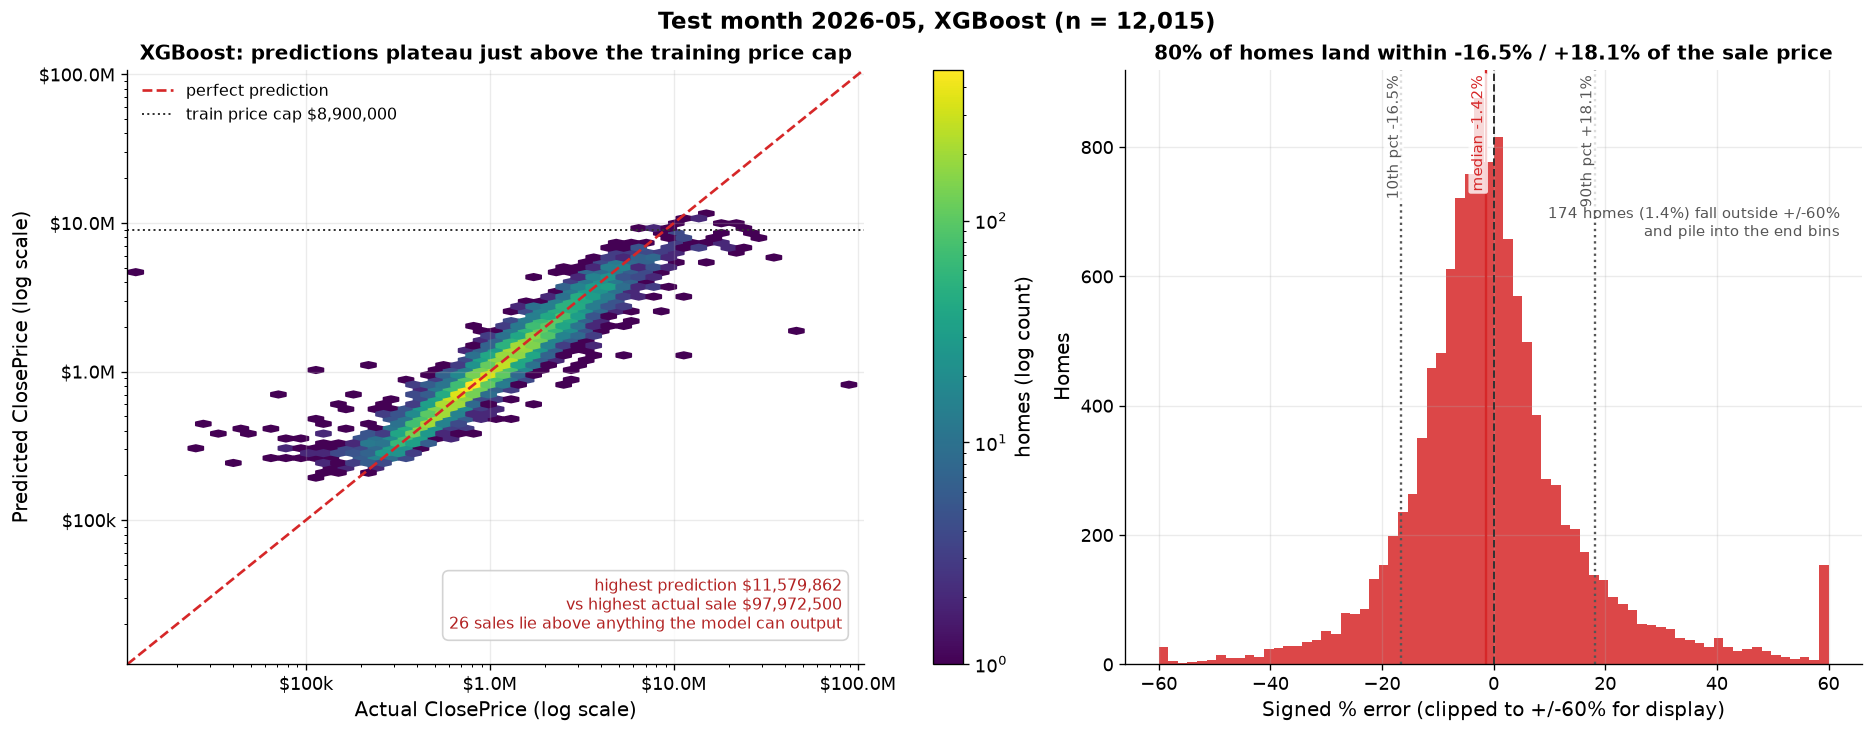


**Practical accuracy of XGBoost on the test month:** 36.3% of homes are predicted within +/-5% of the
actual sale price, 61.0% within +/-10% and 84.5% within +/-20%. The median signed error is
-1.42%, so there is no large global bias - the bias is segment-specific (section 3) rather than overall.


In [16]:
# Produces: Figure 6 - actual versus predicted, and the distribution of percent error
# Figure 6: actual vs predicted for the headline model (w8_fig6)
yp = preds[HEADLINE].to_numpy(float)
cap = TRAIN_CAP
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6), constrained_layout=True)
hb = axes[0].hexbin(y_test, yp, xscale='log', yscale='log', gridsize=48, bins='log', cmap='viridis', mincnt=1)
lims = [min(y_test.min(), yp.min()) * 0.9, max(y_test.max(), yp.max()) * 1.1]
axes[0].plot(lims, lims, color='#d62728', lw=1.6, ls='--', label='perfect prediction')
axes[0].axhline(cap, color='#333333', lw=1.2, ls=':', label=f'train price cap {usd(cap)}')
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('Actual ClosePrice (log scale)'); axes[0].set_ylabel('Predicted ClosePrice (log scale)')
axes[0].xaxis.set_major_formatter(ps.usd); axes[0].yaxis.set_major_formatter(ps.usd)
axes[0].legend(loc='upper left', fontsize=9.5)
n_above = int((y_test > yp.max()).sum())
axes[0].annotate(f'highest prediction {usd(yp.max())}\nvs highest actual sale {usd(y_test.max())}\n'
                 f'{n_above} sales lie above anything the model can output',
                 (0.97, 0.06), xycoords='axes fraction', ha='right', fontsize=9.5, color='#b22222',
                 bbox=dict(fc='white', ec='#cccccc', alpha=0.85, boxstyle='round,pad=0.4'))
axes[0].set_title(f'{HEADLINE}: predictions plateau just above the training price cap', fontsize=12)
fig.colorbar(hb, ax=axes[0], label='homes (log count)')

pe = 100 * (yp - y_test) / y_test
axes[1].hist(np.clip(pe, -60, 60), bins=70, color=ps.MODEL_COLORS[HEADLINE], alpha=0.85)
axes[1].axvline(0, color='#333333', lw=1.2, ls='--')
med, p10, p90 = np.median(pe), np.percentile(pe, 10), np.percentile(pe, 90)
for v, lab, c in [(med, f'median {med:+.2f}%', '#d62728'), (p10, f'10th pct {p10:+.1f}%', '#555555'),
                  (p90, f'90th pct {p90:+.1f}%', '#555555')]:
    axes[1].axvline(v, color=c, lw=1.4, ls='-' if c == '#d62728' else ':')
    axes[1].annotate(lab, (v, axes[1].get_ylim()[1] * 0.99), rotation=90, fontsize=9,
                     ha='right', va='top', color=c,
                     bbox=dict(fc='white', ec='none', alpha=0.8, boxstyle='round,pad=0.15'))
n_clip = int((np.abs(pe) > 60).sum())
axes[1].annotate(f'{n_clip} homes ({100*n_clip/len(pe):.1f}%) fall outside +/-60%\nand pile into the end bins',
                 (0.97, 0.72), xycoords='axes fraction', ha='right', fontsize=9, color='#555555')
axes[1].set_xlabel('Signed % error (clipped to +/-60% for display)')
axes[1].set_ylabel('Homes')
axes[1].set_title(f'80% of homes land within {p10:+.1f}% / {p90:+.1f}% of the sale price', fontsize=12)
fig.suptitle(f'Test month 2026-05, {HEADLINE} (n = {len(y_test):,})', fontsize=14, fontweight='bold')
print('saved:', ps.save(fig, 'w8_fig6_actual_vs_predicted.png'))
plt.show()

within = lambda t: 100 * np.mean(np.abs(pe) <= t)
display(Markdown(f'''
**Practical accuracy of {HEADLINE} on the test month:** {within(5):.1f}% of homes are predicted within +/-5% of the
actual sale price, {within(10):.1f}% within +/-10% and {within(20):.1f}% within +/-20%. The median signed error is
{med:+.2f}%, so there is no large global bias - the bias is segment-specific (section 3) rather than overall.
'''))

### Step 17: What this week establishes

**What this shows:** The closing summary and the limitations, written from the saved tables so every figure matches the ones above. The four points answer the four questions this notebook opened with.

**Results:** In May 2026 XGBoost misses a typical home by 7.38%. Where the model is used - which price level, which county - matters more than which of these five algorithms is chosen.

In [17]:
# Produces: the closing summary and the limitations list
b = summary.sort_values('MdAPE').iloc[0]
rf = summary[summary.model.eq('RF')].iloc[0]
lr = summary[summary.model.eq('LR')].iloc[0]
qq = band[band.scope.eq('train_quintile') & band.model.eq(HEADLINE)].sort_values('order')
ff = band[band.scope.eq('fixed_band') & band.model.eq(HEADLINE)].sort_values('order')
cc = county[county.model.eq(HEADLINE) & ~county.group.str.contains('Other')].sort_values('MdAPE')
ea = bk[~bk.cutoff.isin(['2026-04', '2026-05']) & bk.model.eq(HEADLINE)]['MdAPE']

display(Markdown(f'''
### What Week 8 adds

1. **A full metric set, not just R2.** {b["model"]} ({b["feature_set"]}) on 2026-05:
   R2 {b["R2"]:.4f}, MAE {usd(b["MAE"])}, RMSE {usd(b["RMSE"])}, MAPE {b["MAPE"]:.2%}, **MdAPE {b["MdAPE"]:.2%}**.
   R2 and MdAPE rank the models differently, and the reason is the price cap, not a better model.
2. **Price band is the dominant driver of error.** {HEADLINE} ranges from {qq["MdAPE"].min():.2%}
   ({qq.loc[qq["MdAPE"].idxmin(), "group"]}) to {qq["MdAPE"].max():.2%}
   ({qq.loc[qq["MdAPE"].idxmax(), "group"]}) - a {100*(qq["MdAPE"].max()-qq["MdAPE"].min()):.2f} pp spread that
   dwarfs the {100*(rf["MdAPE"]-b["MdAPE"]):.2f} pp gap between the best and second-tier *models*. Choosing where to
   apply the AVM matters more than choosing between these algorithms.
3. **Geography matters mostly through price level.** County MdAPE runs {cc["MdAPE"].min():.2%}
   ({cc.iloc[0]["group"]}) to {cc["MdAPE"].max():.2%} ({cc.iloc[-1]["group"]}), tracking county median sale price.
4. **The ranking survives time.** Across {len(cuts)} scored months the model order is stable; the headline model's
   MdAPE moves between {ea.min():.2%} and {ea.max():.2%} on genuinely out-of-sample cutoffs.

### Limitations (read before quoting any number above)

- **Hyperparameters were tuned on a single validation month (2026-04)** and frozen. The backtest re-uses them at
  earlier cutoffs, so it demonstrates stability, not independent tuning. The 2026-04 cutoff is the tuning month
  itself and is optimistic.
- **The saved production model was picked by test MdAPE** among the five finalists (Week 7), so
  {HEADLINE}'s {b["MdAPE"]:.2%} is slightly optimistic; {HEADLINE} and LightGBM are statistically tied
  (Week 7 bootstrap CI for the difference: -0.15 to +0.13 pp) and strict validation-based selection picks LightGBM.
- **No ZIP-level conclusions.** The largest test ZIP has {int(test["PostalCode"].value_counts().iloc[0])} sales and
  none reaches n = {MIN_N}. County is the finest supportable unit, and {int(county[county.group.str.contains("Other")]["n"].iloc[0]):,}
  homes sit in pooled small counties where the model is effectively unvalidated.
- **Tree models cannot price above the training cap** ({usd(TRAIN_CAP)}), so luxury error is structural, not tunable.
- **Bootstrap intervals here are not simultaneous.** Many groups are compared; a single interval that barely
  excludes zero (see the marginal contrast in 3d) should not be read as a firm finding.
- **LightGBM remains capped at ~2,000 trees** at every cutoff, so its numbers are a lower bound.
- **One market, one window.** Everything is CRMLS single-family California, 2024-11..2026-05. Nothing here
  establishes behaviour in a different market or a different rate environment.
'''))


### What Week 8 adds

1. **A full metric set, not just R2.** XGBoost (F0) on 2026-05:
   R2 0.4934, MAE $198,830, RMSE $1,193,246, MAPE 15.68%, **MdAPE 7.38%**.
   R2 and MdAPE rank the models differently, and the reason is the price cap, not a better model.
2. **Price band is the dominant driver of error.** XGBoost ranges from 5.33%
   (Q2 575-785k) to 11.60%
   (Q5 >1.59M) - a 6.27 pp spread that
   dwarfs the 0.81 pp gap between the best and second-tier *models*. Choosing where to
   apply the AVM matters more than choosing between these algorithms.
3. **Geography matters mostly through price level.** County MdAPE runs 5.63%
   (Riverside) to 10.17% (Alameda), tracking county median sale price.
4. **The ranking survives time.** Across 4 scored months the model order is stable; the headline model's
   MdAPE moves between 7.45% and 7.64% on genuinely out-of-sample cutoffs.

### Limitations (read before quoting any number above)

- **Hyperparameters were tuned on a single validation month (2026-04)** and frozen. The backtest re-uses them at
  earlier cutoffs, so it demonstrates stability, not independent tuning. The 2026-04 cutoff is the tuning month
  itself and is optimistic.
- **The saved production model was picked by test MdAPE** among the five finalists (Week 7), so
  XGBoost's 7.38% is slightly optimistic; XGBoost and LightGBM are statistically tied
  (Week 7 bootstrap CI for the difference: -0.15 to +0.13 pp) and strict validation-based selection picks LightGBM.
- **No ZIP-level conclusions.** The largest test ZIP has 74 sales and
  none reaches n = 200. County is the finest supportable unit, and 1,386
  homes sit in pooled small counties where the model is effectively unvalidated.
- **Tree models cannot price above the training cap** ($8,900,000), so luxury error is structural, not tunable.
- **Bootstrap intervals here are not simultaneous.** Many groups are compared; a single interval that barely
  excludes zero (see the marginal contrast in 3d) should not be read as a firm finding.
- **LightGBM remains capped at ~2,000 trees** at every cutoff, so its numbers are a lower bound.
- **One market, one window.** Everything is CRMLS single-family California, 2024-11..2026-05. Nothing here
  establishes behaviour in a different market or a different rate environment.


## Limitations and next steps

**Limitations**

- **The settings were tuned on a single month.** Every setting was chosen on April 2026 and then frozen. The
  time test re-uses those same settings at earlier months, so it shows the configuration is stable; it is not
  the same as re-tuning honestly at each point in time, and the April month is the one the settings came from,
  so its numbers flatter the models.
- **R-squared is not a safe headline here.** A few sales recorded in the hundreds of millions - the largest is
  \$989,500,000 - hold up to 98% of a single month's price variation, and at the three earlier
  months no model's R-squared rises above 0.0218. That is a data quality artefact rather than the
  model getting worse, which is why only the percent-error measures are compared across months.
- **No claims below county level.** May 2026 covers 1,073 ZIP codes and the largest holds 74
  sales, so county is the finest geography these results can defend. 1,386 homes sit in the
  43 pooled small counties, where the model is effectively unvalidated.
- **The saved model was chosen on the test month.** XGBoost beat LightGBM on test typical error
  (7.38% against 7.40%), but the two are statistically tied and a strict
  validation-based choice would have picked LightGBM, so 7.38% is slightly optimistic.
- **LightGBM still runs into its tree limit** - it used 1,994 to 2,022 trees against
  a 2,000-tree ceiling in every month tested - so its numbers are a floor on what it could do, not its best.
- **One market, one window, one test month.** Everything here is California single-family homes from the CRMLS
  feed between 2024-11 and 2026-05, with every test-month figure drawn from May 2026 alone. Nothing here
  establishes how the model behaves in another market or another rate environment.

**Next steps**

- Lift the LightGBM tree cap and re-tune on more than one validation month.
- Add features that explain value at the top of the market - view, finish quality, lot shape - because that is
  where the error is, and no amount of tuning replaces a missing feature.
- Quote an estimate with its price level attached: in the middle of the market it is worth trusting, while for
  homes above three million dollars (the >3M band, median sale
  \$4,050,000, typical error 15.9%) it is an indication rather
  than a valuation.